# 16 · A Realistic Ring: Spectral Purity and the Ring Card

**Question:** what are the realistic parameters of an improved ring source, using only physics we can model and loss and Q values that have been published, and which design levers improve it?

**Answer in advance:**
- A single ring pumped by short pulses has a **hard purity limit of 11/12 = 0.917**. Kues et al. 2017 measured g⁽²⁾ = 1.92 per resonance, which sits at that limit.
- A pump resonance $r$ times broader than the signal and idler lifts the limit to $P_\text{max} = 1 - 1/((2r+1)(3r+1))$, checked here against a singular value decomposition.
- Which ring to build depends on the use. **QKD** from one source needs escape efficiency, linewidth, brightness and bins; purity matters little. **Gates** with photons from several sources need purity as well.
- Model **ratios** between designs are reliable. **Absolute pair rates are not**: they come out up to 237× too high against a published ring.

```
joint spectral amplitude ─▶ purity (SVD) ─▶ closed form P_max ─▶ Kues g2 = 1.92 ─▶ purity vs brightness ─▶ QKD ring, gate ring ─▶ what is not reliable
```

The ring cards in [`data/ring_cards.json`](../data/ring_cards.json) are exact transfer-matrix results on the waveguide of notebook 13, with intrinsic $Q_i = 10^7$ (published for low-loss silicon nitride rings, arXiv:2404.13387). The cross-section is kept for both loss cases; a real low-loss platform would have a different geometry.

In [1]:
import numpy as np
import qutip as qt
import perceval as pcvl
import json, os, time
from scipy.signal import fftconvolve, lfilter
from scipy.special import gammaln, jn_zeros
from scipy.optimize import minimize_scalar
import matplotlib.pyplot as plt

results = []   # every theory-vs-simulation check is recorded here
t_start = time.time()

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its independent value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol, rtol=0))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.5f}, check = {theory:.5f}")

## 1. The joint spectral amplitude of one ring

**Plain words:** a photon pair is described by a two-dimensional spectrum $F(\omega_s, \omega_i)$. Energy conservation with the pump gives a diagonal stripe; the two resonances give a cross. When the pair's spectrum cannot be written as a product $f(\omega_s)\,g(\omega_i)$, detecting one photon leaves the other in a mixture. It is like a 2D optical transfer function that is not separable. The **purity** measures this: the sum of squared Schmidt weights from an SVD of $F$.

$$F(\omega_s,\omega_i) = P(\omega_s+\omega_i)\,\ell_s(\omega_s)\,\ell_i(\omega_i),\quad \ell(\Delta) = \frac{1}{G/2 - i\Delta},\quad P = a * a,\quad a(\omega) = \alpha(\omega)\,\ell_p(\omega)$$

The pump is Gaussian, $\alpha \propto e^{-\omega^2/4\sigma^2}$, with $\sigma$ its intensity sigma. Frequencies are in units of the signal and idler linewidth, $G_s = G_i = 1$.

**Gap:** low gain, one pump resonance, no self- or cross-phase modulation and no pump depletion.

**One sentence:** purity is how close the pair's two-dimensional spectrum is to a product.

In [2]:
def alpha(w, sig):
    """Pump field spectrum, normalised so that the integral of |alpha|^2 is 1."""
    return np.exp(-w ** 2 / (4 * sig ** 2)) / np.sqrt(sig * np.sqrt(2 * np.pi))

def lorentz(w, G):
    return 1 / (G / 2 - 1j * w)

def jsa(sig, Gp=1.0, L=40.0, dw=0.1):
    """F(ws, wi) on a uniform grid |w| <= L. The pump self-convolution covers every W = ws + wi."""
    n = int(round(L / dw))
    w = np.arange(-n, n + 1) * dw
    m = int(round(max(2 * L, 12 * sig) / dw))
    wp = np.arange(-m, m + 1) * dw
    a = alpha(wp, sig) * lorentz(wp, Gp)
    P = fftconvolve(a, a) * dw
    i, j = np.indices((w.size, w.size))
    return P[i + j - 2 * n + 2 * m] * lorentz(w[i], 1.0) * lorentz(w[j], 1.0)

def schmidt(F):
    s = np.linalg.svd(F, compute_uv=False)
    return s ** 2 / np.sum(s ** 2)

def purity_svd(F):
    return float(np.sum(schmidt(F) ** 2))

def purity_rho(F):
    """The same number without an SVD: Tr[rho^2] / Tr[rho]^2, rho = F^dagger F. Much faster, used for sweeps."""
    rho = F.conj().T @ F
    return float(np.sum(np.abs(rho) ** 2) / np.real(np.trace(rho)) ** 2)

def grid_for(sig):
    return (40.0 if sig >= 0.4 else 10.0), min(0.1, sig / 4)

# Second method with no spectral grid: the biphoton in time. a' = -(G_p/2) a + pump(t), and
# psi(ts, ti) = exp(-(ts + ti)/2) * integral over t < min(ts, ti) of a(t)^2 exp(t) dt, with G_s = G_i = 1.
def biphoton_time(sig, Gp=1.0, dt=0.04, Tdecay=30.0):
    t0, t1 = -4.5 / sig, Tdecay + 4.5 / sig
    dtf = min(0.005, 0.1 / sig)
    tf = np.arange(t0, t1, dtf)
    src = np.exp(-sig ** 2 * tf ** 2) * sig / np.sqrt(np.pi) / np.sqrt(sig * np.sqrt(2 * np.pi))
    e = np.exp(-Gp / 2 * dtf)
    a = lfilter([dtf / 2, dtf / 2 * e], [1, -e], src)
    S = a ** 2 * np.exp(tf)
    Q = np.concatenate(([0], np.cumsum(dtf / 2 * (S[1:] + S[:-1]))))
    t = np.arange(t0, t1, dt)
    Qt = np.interp(t, tf, Q)
    i, j = np.indices((t.size, t.size))
    return np.exp(-(t[i] + t[j]) / 2) * Qt[np.minimum(i, j)]

print(" sigma / G   purity (SVD)   purity (time domain)")
sigmas = (0.1, 0.3, 0.5, 1.0, 2.0, 5.0)
pur_sig = {}
for s in sigmas:
    L, dw = grid_for(s)
    F_ = jsa(s, L=L, dw=dw)
    pf = purity_svd(F_)
    pt = purity_rho(biphoton_time(s, dt=0.04 if s >= 0.5 else 0.08))
    pur_sig[s] = pf
    print(f"   {s:5.1f}      {pf:.4f}         {pt:.4f}")
    check(f"sigma = {s}: SVD vs time-domain method", pf, pt, tol=1e-3)
    check(f"sigma = {s}: SVD vs Tr[rho^2]/Tr[rho]^2", pf, purity_rho(F_), tol=1e-10)
# Convergence, grid doubled in span and halved in step
check("convergence, sigma = 1: span doubled", purity_rho(jsa(1.0, L=20)), purity_rho(jsa(1.0, L=40)), tol=1e-3)
check("convergence, sigma = 1: step halved", purity_rho(jsa(1.0, L=20)), purity_rho(jsa(1.0, L=20, dw=0.05)), tol=1e-3)
# Test spectra with known answers
wt = np.arange(-20, 20.001, 0.05)
u0, u1 = np.exp(-wt ** 2 / 8), wt * np.exp(-wt ** 2 / 8)
u0, u1 = u0 / np.linalg.norm(u0), u1 / np.linalg.norm(u1)
check("separable test spectrum: purity vs 1", purity_svd(np.outer(u0, u0)), 1.0, tol=1e-12)
check("two-mode test spectrum, weights 0.8 and 0.2: purity vs 0.68", purity_svd(np.sqrt(0.8) * np.outer(u0, u0) + np.sqrt(0.2) * np.outer(u1, u1)), 0.68, tol=1e-12)
# CW limit: a very narrow pump collapses the spectrum onto a line, and purity falls linearly with sigma
s_cw = 0.03
check("narrow pump, sigma = 0.03: purity vs the limit sigma sqrt(8 pi) 5/(2 pi) (0.006)", purity_rho(jsa(s_cw, L=6.0, dw=s_cw / 4)), s_cw * np.sqrt(8 * np.pi) * 5 / (2 * np.pi), tol=0.006)

 sigma / G   purity (SVD)   purity (time domain)


     0.1      0.3550         0.3548
PASS  sigma = 0.1: SVD vs time-domain method: simulation = 0.35497, check = 0.35478
PASS  sigma = 0.1: SVD vs Tr[rho^2]/Tr[rho]^2: simulation = 0.35497, check = 0.35497
     0.3      0.6873         0.6869
PASS  sigma = 0.3: SVD vs time-domain method: simulation = 0.68728, check = 0.68691
PASS  sigma = 0.3: SVD vs Tr[rho^2]/Tr[rho]^2: simulation = 0.68728, check = 0.68728


     0.5      0.7991         0.7990
PASS  sigma = 0.5: SVD vs time-domain method: simulation = 0.79909, check = 0.79901
PASS  sigma = 0.5: SVD vs Tr[rho^2]/Tr[rho]^2: simulation = 0.79909, check = 0.79909


     1.0      0.8800         0.8799
PASS  sigma = 1.0: SVD vs time-domain method: simulation = 0.88001, check = 0.87992
PASS  sigma = 1.0: SVD vs Tr[rho^2]/Tr[rho]^2: simulation = 0.88001, check = 0.88001


     2.0      0.9081         0.9080
PASS  sigma = 2.0: SVD vs time-domain method: simulation = 0.90809, check = 0.90800
PASS  sigma = 2.0: SVD vs Tr[rho^2]/Tr[rho]^2: simulation = 0.90809, check = 0.90809


     5.0      0.9158         0.9157
PASS  sigma = 5.0: SVD vs time-domain method: simulation = 0.91579, check = 0.91570
PASS  sigma = 5.0: SVD vs Tr[rho^2]/Tr[rho]^2: simulation = 0.91579, check = 0.91579
PASS  convergence, sigma = 1: span doubled: simulation = 0.88003, check = 0.88001
PASS  convergence, sigma = 1: step halved: simulation = 0.88003, check = 0.88003


PASS  separable test spectrum: purity vs 1: simulation = 1.00000, check = 1.00000
PASS  two-mode test spectrum, weights 0.8 and 0.2: purity vs 0.68: simulation = 0.68000, check = 0.68000


PASS  narrow pump, sigma = 0.03: purity vs the limit sigma sqrt(8 pi) 5/(2 pi) (0.006): simulation = 0.11827, check = 0.11968


**A CW pump is not pure at all.** Purity falls towards 0 as the pump narrows, and a long pulse is close to the CW source of a QKD experiment. That costs nothing there, because frequency-bin QKD from one source interferes each photon pair with itself, not with a photon from another source.

## 2. A closed form for the purity limit

For a broad pump the pump spectrum is flat, so $P(W) \propto 1/(r - iW)$ with $r = G_p/G_s$. The limit does not depend on any other parameter. In time, the kernel has Schmidt values proportional to $1/j^2$, with $j$ the zeros of a Bessel function $J_{-\nu}$, $\nu = (r-1)/r$, and Rayleigh's sums of $j^{-4}$ and $j^{-8}$ give

$$P_\text{max}(r) = 1 - \frac{1}{(2r+1)(3r+1)}, \qquad P_\text{max}(1) = \frac{11}{12}$$

This form was derived here and is verified numerically below, not taken from a paper. At $r = 1$ the sum runs over the zeros of $J_0$.

**Gap:** the form holds for a broad pump, where the pulse is short and brightness is low. Real designs stop before this limit.

In [3]:
P_max = lambda r: 1 - 1 / ((2 * r + 1) * (3 * r + 1))
n, dw = 400, 0.1
wg = np.arange(-n, n + 1) * dw
i, j = np.indices((wg.size, wg.size))
print(" r    P_max closed form   SVD of the broad-pump spectrum")
for r in (1, 2, 3, 5, 10):
    F_ = 2 * np.pi / (r - 1j * (wg[i] + wg[j])) * lorentz(wg[i], 1) * lorentz(wg[j], 1)
    p = purity_svd(F_)
    print(f" {r:2d}   {P_max(r):.5f}            {p:.5f}")
    check(f"r = {r}: SVD vs P_max", p, P_max(r), tol=5e-4)
jz = jn_zeros(0, 400)
check("r = 1: Rayleigh sum over zeros of J_0, sum j^-8 / (sum j^-4)^2, vs 11/12", np.sum(jz ** -8.0) / np.sum(jz ** -4.0) ** 2, 11 / 12, tol=1e-6)
for r in (1, 3):
    best = max(purity_rho(biphoton_time(s, Gp=r, dt=0.02)) for s in (10, 30, 100))
    check(f"r = {r}: time-domain purity with a short pulse vs P_max", best, P_max(r), tol=5e-4)

 r    P_max closed form   SVD of the broad-pump spectrum


  1   0.91667            0.91667
PASS  r = 1: SVD vs P_max: simulation = 0.91667, check = 0.91667


  2   0.97143            0.97144
PASS  r = 2: SVD vs P_max: simulation = 0.97144, check = 0.97143


  3   0.98571            0.98573
PASS  r = 3: SVD vs P_max: simulation = 0.98573, check = 0.98571


  5   0.99432            0.99435
PASS  r = 5: SVD vs P_max: simulation = 0.99435, check = 0.99432


 10   0.99846            0.99851
PASS  r = 10: SVD vs P_max: simulation = 0.99851, check = 0.99846
PASS  r = 1: Rayleigh sum over zeros of J_0, sum j^-8 / (sum j^-4)^2, vs 11/12: simulation = 0.91667, check = 0.91667


PASS  r = 1: time-domain purity with a short pulse vs P_max: simulation = 0.91664, check = 0.91667


PASS  r = 3: time-domain purity with a short pulse vs P_max: simulation = 0.98569, check = 0.98571


## 3. Kues et al. 2017: g⁽²⁾ = 1.92 is the single-ring limit

**Plain words:** one arm of a pair source, without its herald, is thermal in each Schmidt mode. Many modes look like a coherent beam, $g^{(2)} \to 1$; one mode is fully thermal, $g^{(2)} = 2$. In between $g^{(2)} = 1 + 1/K$, with $K$ the Schmidt number and $1/K$ the purity (notebook 10).

Kues et al. measured $g^{(2)} = 1.92$ per resonance, so $K = 1.086$. With $P_\text{max}(1) = 11/12$ the model gives **1.917**: their ring sits at the single-ring limit, which also means a single ring cannot do better.

**Gap:** a measured $g^{(2)}$ agrees with this limit only if their pump is short compared with the ring lifetime. The reading is supported by their pulsed pump, not proven by it.

In [4]:
def g2_thermal(weights, mu=0.05, nmax=30):
    """Independent thermal Schmidt modes: photon-number distribution by convolution, then g2 = <n(n-1)>/<n>^2. No use of g2 = 1 + purity."""
    dist = np.array([1.0])
    n_ = np.arange(nmax)
    for wk in weights[:40]:
        m = mu * wk
        dist = np.convolve(dist, m ** n_ / (1 + m) ** (n_ + 1))[:3 * nmax]
    k = np.arange(dist.size)
    return float(np.sum(k * (k - 1) * dist) / np.sum(k * dist) ** 2)

def g2_negbin(K, mu=0.05, nmax=60):
    """Notebook 10: K modes give a negative binomial pair number."""
    n_ = np.arange(nmax)
    x = mu / (mu + K)
    p = np.exp(gammaln(n_ + K) - gammaln(n_ + 1) - gammaln(K) + n_ * np.log(x) + K * np.log(1 - x))
    return float(np.sum(n_ * (n_ - 1) * p) / np.sum(n_ * p) ** 2)

for s, r in ((1.0, 1), (5.0, 1), (3.0, 3)):
    w_ = schmidt(jsa(s, Gp=r))
    P_ = float(np.sum(w_ ** 2))
    check(f"sigma {s}, r {r}: g2 of thermal Schmidt modes vs 1 + purity", g2_thermal(w_), 1 + P_, tol=1e-3)
    check(f"sigma {s}, r {r}: negative binomial with K = 1/purity vs thermal modes", g2_negbin(1 / P_), g2_thermal(w_), tol=1e-3)
g2_limit = 1 + 11 / 12
print(f"single-ring limit: g2 = {g2_limit:.3f}, K = {12 / 11:.3f}; Kues et al. 2017: g2 = 1.92, K = 1.086, purity {1 / 1.086:.3f}")
check("g2 at the single-ring limit vs Kues et al. 2017 (1.92)", g2_limit, 1.92, tol=0.005)
check("K at the limit vs measured 1.086", 12 / 11, 1.086, tol=0.006)

PASS  sigma 1.0, r 1: g2 of thermal Schmidt modes vs 1 + purity: simulation = 1.88002, check = 1.88001
PASS  sigma 1.0, r 1: negative binomial with K = 1/purity vs thermal modes: simulation = 1.88001, check = 1.88002


PASS  sigma 5.0, r 1: g2 of thermal Schmidt modes vs 1 + purity: simulation = 1.91579, check = 1.91579
PASS  sigma 5.0, r 1: negative binomial with K = 1/purity vs thermal modes: simulation = 1.91579, check = 1.91579


PASS  sigma 3.0, r 3: g2 of thermal Schmidt modes vs 1 + purity: simulation = 1.98012, check = 1.98012
PASS  sigma 3.0, r 3: negative binomial with K = 1/purity vs thermal modes: simulation = 1.98012, check = 1.98012
single-ring limit: g2 = 1.917, K = 1.091; Kues et al. 2017: g2 = 1.92, K = 1.086, purity 0.921
PASS  g2 at the single-ring limit vs Kues et al. 2017 (1.92): simulation = 1.91667, check = 1.92000
PASS  K at the limit vs measured 1.086: simulation = 1.09091, check = 1.08600


## 4. Purity costs brightness

A broader pump resonance raises the purity limit but weakens the pump field in the ring. At fixed pulse energy the relative pair probability is

$$B = G_p^2\,G_s G_i \iint |F|^2\,d\omega_s\,d\omega_i$$

with the signal and idler integral done exactly, so no Lorentzian tail is cut. $B = 1$ is the brightest single ring.

**Gap:** $G_p/G_s$ is a free number here. A real coupler sets it through a Mach–Zehnder coupler, which also makes it alternate between bins (section 5).

**One sentence:** every step above 0.92 in purity is paid for in pair rate.

brightest single ring: sigma/G = 0.305, purity there 0.692
PASS  r = 1, sigma = 100: B vs broad-pump limit (2 pi)^3/sigma^2 r/(r + 1) (relative): simulation = 0.99203, check = 1.00000
PASS  r = 1, sigma = 0.01: B vs narrow-pump limit 128 pi^1.5 sigma/r^2 (relative): simulation = 0.99860, check = 1.00000
PASS  r = 3, sigma = 100: B vs broad-pump limit (2 pi)^3/sigma^2 r/(r + 1) (relative): simulation = 0.97633, check = 1.00000
PASS  r = 3, sigma = 0.01: B vs narrow-pump limit 128 pi^1.5 sigma/r^2 (relative): simulation = 0.99967, check = 1.00000


PASS  sigma = 1: B from the 1D formula vs a 2D sum on the spectrum (relative): simulation = 1.00000, check = 1.00000


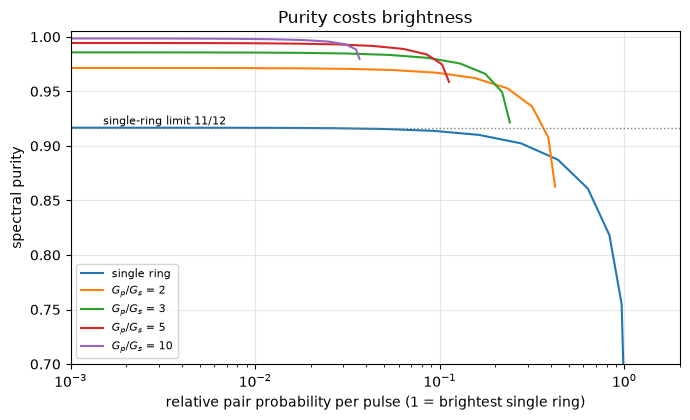

In [5]:
def brightness(sig, Gp=1.0):
    d = min(0.02, sig / 10)
    m = int(round(12 * sig / d))
    w = np.arange(-m, m + 1) * d
    a = alpha(w, sig) * lorentz(w, Gp)
    P = fftconvolve(a, a) * d
    W = np.arange(-2 * m, 2 * m + 1) * d
    # int |l_s(ws)|^2 |l_i(W - ws)|^2 dws = (2 pi)^2 (1/pi) / (1 + W^2) for G_s = G_i = 1
    return float(Gp ** 2 * np.sum(np.abs(P) ** 2 * (2 * np.pi) ** 2 / (np.pi * (1 + W ** 2))) * d)

res = minimize_scalar(lambda x: -brightness(np.exp(x)), bounds=(np.log(0.1), np.log(10)), method="bounded")
sig_ref, B_ref = float(np.exp(res.x)), float(-res.fun)
print(f"brightest single ring: sigma/G = {sig_ref:.3f}, purity there {purity_rho(jsa(sig_ref, L=40, dw=0.1)):.3f}")
for r in (1, 3):
    check(f"r = {r}, sigma = 100: B vs broad-pump limit (2 pi)^3/sigma^2 r/(r + 1) (relative)", brightness(100.0, r) / ((2 * np.pi) ** 3 / 100 ** 2 * r / (r + 1)), 1.0, tol=0.03)
    check(f"r = {r}, sigma = 0.01: B vs narrow-pump limit 128 pi^1.5 sigma/r^2 (relative)", brightness(0.01, r) / (128 * np.pi ** 1.5 * 0.01 / r ** 2), 1.0, tol=0.03)
F_ = jsa(1.0, L=40.0, dw=0.05)
check("sigma = 1: B from the 1D formula vs a 2D sum on the spectrum (relative)", brightness(1.0) / (np.sum(np.abs(F_) ** 2) * 0.05 ** 2), 1.0, tol=0.02)

sig_grid = np.logspace(-0.7, 2, 19)
curves = {r: [(brightness(float(s), r) / B_ref, purity_rho(jsa(float(s), Gp=r, L=grid_for(float(s))[0], dw=grid_for(float(s))[1]))) for s in sig_grid] for r in (1, 2, 3, 5, 10)}
fig, ax = plt.subplots(figsize=(7, 4.3))
for r, c in curves.items():
    i_top = int(np.argmax([x[0] for x in c]))
    ax.plot([x[0] for x in c[i_top:]], [x[1] for x in c[i_top:]], "-", label="single ring" if r == 1 else f"$G_p/G_s$ = {r}")
ax.axhline(11 / 12, color="gray", ls=":", lw=1)
ax.text(1.5e-3, 11 / 12 + 0.003, "single-ring limit 11/12", fontsize=8)
ax.set_xscale("log"); ax.set_xlim(1e-3, 2); ax.set_ylim(0.7, 1.005)
ax.set_xlabel("relative pair probability per pulse (1 = brightest single ring)"); ax.set_ylabel("spectral purity")
ax.set_title("Purity costs brightness"); ax.legend(fontsize=8); ax.grid(alpha=0.3)
fig.tight_layout(); plt.show()

## 5. The ring cards

Each card is a whole design: exact ring values for the geometry, with the choice of ring set by the use.

- **Kues 2017 ring:** the reference, on the assumed cross-section with 0.06 dB/cm.
- **QKD ring:** a single ring with $Q_i = 10^7$ and $Q_L = 235{,}000$. All bins stay identical, with maximum escape efficiency and CW brightness. Purity is not the target.
- **Gate ring:** a Mach–Zehnder coupler with $r = 5$, $Q_s = 100{,}000$, $Q_i = 10^7$, pump width chosen for purity ≥ 0.98. Brightness is reported at that point, not at the brightest point. A periodic coupler makes alternate bins broad, so only odd $k$ have $r \ge 2$.

In [6]:
with open(os.path.join("..", "data", "ring_cards.json"), encoding="utf-8") as fh:
    cards = json.load(fh)
D = cards["designs"]
names = {"kues_2017": "Kues 2017 ring", "qkd": "QKD ring", "gate": "Gate ring"}
rows = [("Q_L pump / signal", lambda d: f"{d['pump']['Q_L']:,.0f} / {d['signal']['Q_L']:,.0f}"),
        ("linewidth pump / signal (MHz)", lambda d: f"{d['pump']['linewidth_Hz'] / 1e6:.0f} / {d['signal']['linewidth_Hz'] / 1e6:.0f}"),
        ("escape efficiency", lambda d: f"{d['signal']['eta_esc']:.4f}"),
        ("coherence time 1/(2G) (ns)", lambda d: f"{d['coherence_time_s'] * 1e9:.3f}"),
        ("r = G_p / G_s", lambda d: f"{d['r']:.2f}"),
        ("purity limit P_max", lambda d: f"{d['purity']['P_max']:.4f}"),
        ("purity at the chosen pump", lambda d: f"{d['purity']['M']:.4f}"),
        ("CW pair rate / Kues ring", lambda d: f"{d['cw_rate_relative_to_kues_ring']:.4f}"),
        ("pulsed brightness (brightest Kues pulse = 1)", lambda d: f"{d['pulsed_brightness_relative']:.4f}"),
        ("rate of bin pair k = 10 / k = 1", lambda d: f"{d['bin_rate_relative_to_k1'][-1]:.3f}")]
print(f"{'':46s}" + "".join(f"{names[k]:>18s}" for k in D))
for lab, fn in rows:
    print(f"{lab:46s}" + "".join(f"{fn(D[k]):>18s}" for k in D))

# Exact all-pass ring from the card's coupling and loss: t = cos(phi), a = round-trip amplitude
for k in ("kues_2017", "qkd"):
    d = D[k]
    g = d["geometry"]
    t, a_ = np.cos(g["phi1"]), 10 ** (-g["loss_dB_per_cm"] * g["L_m"] * 100 / 20)
    fwhm = g["FSR_Hz"] * 2 * np.arccos(2 * t * a_ / (1 + (t * a_) ** 2)) / (2 * np.pi)
    check(f"regression: {names[k]}: linewidth from t and a vs the card (MHz)", fwhm / 1e6, d["signal"]["linewidth_Hz"] / 1e6, tol=1.0)
    check(f"regression: {names[k]}: escape efficiency (1 - t^2)/(1 - t^2 a^2) vs the card", (1 - t ** 2) / (1 - (t * a_) ** 2), d["signal"]["eta_esc"], tol=1e-4)
    check(f"regression: {names[k]}: coherence time 1/(2 G) vs the card (ns)", 1 / (2 * d["signal"]["linewidth_Hz"]) * 1e9, d["coherence_time_s"] * 1e9, tol=1e-6)
check("Kues ring linewidth vs about 800 MHz published (MHz, 5 %)", D["kues_2017"]["signal"]["linewidth_Hz"] / 1e6, 800, tol=40)
check("Kues ring coherence time vs about 0.6 ns published", D["kues_2017"]["coherence_time_s"] * 1e9, 0.6, tol=0.03)
# Purity at the card's pump width, recomputed here from the spectrum
for k, r_, s_ in (("kues_2017", 1, D["kues_2017"]["purity"]["sig_over_Gs"]), ("gate", 5, D["gate"]["purity"]["sig_over_Gs"])):
    check(f"regression: {names[k]}: purity from this notebook's spectrum at the card's pump width vs the card", purity_rho(jsa(s_, Gp=r_)), D[k]["purity"]["M"], tol=1e-3)
check("regression: gate ring: P_max(r = 5) vs the card", P_max(5), D["gate"]["purity"]["P_max"], tol=1e-6)
# The CW rate law: pump field ~ eta_in / G_p^2, pair rate ~ 1/G_s, out-coupling ~ eta_s eta_i
def cw_rel(k):
    d, d0 = D[k], D["kues_2017"]
    return ((d["pump"]["eta_in"] / d0["pump"]["eta_in"]) ** 2 * (d0["pump"]["linewidth_Hz"] / d["pump"]["linewidth_Hz"]) ** 2
            * (d0["signal"]["linewidth_Hz"] / d["signal"]["linewidth_Hz"]) * (d["signal"]["eta_esc"] * d["idler"]["eta_esc"]) / (d0["signal"]["eta_esc"] * d0["idler"]["eta_esc"]))
for k in ("qkd", "gate"):
    check(f"regression: {names[k]}: CW rate ratio from the rate law vs the card (relative)", cw_rel(k) / D[k]["cw_rate_relative_to_kues_ring"], 1.0, tol=0.005)
# Dispersion: the same rule as notebook 13, with the card's linewidth
with open(os.path.join("..", "projects", "ring-resonator-design", "results", "s19_dispersion.json")) as fh:
    ds = json.load(fh)
d10 = ds["bins_vs_D_scale"]["1"]["bins"][-1]["Delta_numeric_Hz"]
check("regression: QKD ring: bin 10 rate vs 1/(1 + (Delta/G)^2) (notebook 13)", D["qkd"]["bin_rate_relative_to_k1"][-1], 1 / (1 + (d10 / D["qkd"]["signal"]["linewidth_Hz"]) ** 2), tol=1e-3)
# Effective coupling of the Mach-Zehnder coupler: sin^2(phi1 + phi2) in phase, sin^2(phi1 - phi2) at the odd bins
g = D["gate"]["geometry"]
ratio = np.sin(g["phi1"] + g["phi2"]) ** 2 / np.sin(g["phi1"] - g["phi2"]) ** 2
print(f"gate ring: small-coupling estimate of r = {ratio:.2f}, exact {D['gate']['r']:.2f} (the long arm also changes the round-trip time)")
check("regression: gate ring: r from sin^2(phi1 + phi2)/sin^2(phi1 - phi2) vs exact (within 20 %)", ratio / D["gate"]["r"], 1.0, tol=0.2)

                                                  Kues 2017 ring          QKD ring         Gate ring
Q_L pump / signal                              232,460 / 232,697 235,000 / 235,240  19,979 / 100,000
linewidth pump / signal (MHz)                          832 / 832         823 / 823       9678 / 1936
escape efficiency                                         0.9551            0.9768            0.9898
coherence time 1/(2G) (ns)                                 0.601             0.608             0.258
r = G_p / G_s                                               1.00              1.00              5.00
purity limit P_max                                        0.9167            0.9167            0.9943
purity at the chosen pump                                 0.9081            0.9081            0.9800
CW pair rate / Kues ring                                  1.0000            1.1301            0.0037
pulsed brightness (brightest Kues pulse = 1)              0.1947            0.2177         

### Gate check with Perceval

Heralds-only fidelity of the heralded CNOT from notebook 15, with $M = 0.98$ and $T$ the escape efficiency. At $T = \eta_\text{esc}$ alone the gate ring clears 0.90, but only with no other loss anywhere: any chip or detector loss takes it below 0.90 at once.

In [7]:
LOGICAL = ((1, 0, 1, 0), (1, 0, 0, 1), (0, 1, 1, 0), (0, 1, 0, 1))
CNOT = {0: 0, 1: 1, 2: 3, 3: 2}
EXP = pcvl.catalog["heralded cnot"].build_experiment()

def heralded_F(M, g2, T):
    nm = pcvl.NoiseModel(indistinguishability=float(M), g2=float(g2), g2_distinguishable=False, transmittance=float(T))
    fid = []
    for i, inp in enumerate(LOGICAL):
        p = pcvl.Processor("SLOS", EXP, noise=nm)
        p.with_input(pcvl.BasicState(list(inp)))
        p.min_detected_photons_filter(0)
        res = p.probs(precision=1e-12)["results"]
        fid.append(res.get(pcvl.BasicState(list(LOGICAL[CNOT[i]])), 0.0))
    return float(np.mean(fid))

print(" extra loss (dB)    T       g2      F here    F card")
for row in cards["gate_check"]:
    f_ = heralded_F(row["M"], row["g2"], row["T"])
    print(f"   {row['extra_loss_dB']:5.1f}          {row['T']:.4f}  {row['g2']:.4f}  {f_:.4f}    {row['F_direct']:.4f}  ({row['g2_case']})")
    check(f"regression: gate ring, {row['extra_loss_dB']} dB extra loss, g2 = {row['g2']:.4f}: Perceval vs the card", f_, row["F_direct"], tol=1e-6)
# The same gate for the other two rings, with g2 = 0.02 as in notebook 14
f_kues, f_qkd = heralded_F(0.92, 0.02, D["kues_2017"]["signal"]["eta_esc"]), heralded_F(11 / 12, 0.02, D["qkd"]["signal"]["eta_esc"])
print(f"Kues ring: M = 0.92 gives F = {f_kues:.3f}. QKD ring at its purity limit 11/12 gives F = {f_qkd:.3f}")
check("Kues ring: heralded CNOT vs about 0.71 (notebook 14)", f_kues, 0.71, tol=0.005)
best_case = heralded_F(D["gate"]["purity"]["M"], cards["gate_check"][0]["g2"], D["gate"]["signal"]["eta_esc"])
print(f"gate ring at T = escape efficiency only: F = {best_case:.3f}; rate about {cards['gate_check'][0]['rate_per_s_at_mu']:.1e} /s at 0.005 pairs per pulse")

 extra loss (dB)    T       g2      F here    F card
     0.0          0.9898  0.0100  0.9125    0.9125  (click herald at this T)
PASS  regression: gate ring, 0.0 dB extra loss, g2 = 0.0100: Perceval vs the card: simulation = 0.91251, check = 0.91251


     0.0          0.9898  0.0195  0.8961    0.8961  (low-efficiency herald, conservative)
PASS  regression: gate ring, 0.0 dB extra loss, g2 = 0.0195: Perceval vs the card: simulation = 0.89606, check = 0.89606
     0.1          0.9672  0.0102  0.8338    0.8338  (click herald at this T)
PASS  regression: gate ring, 0.1 dB extra loss, g2 = 0.0102: Perceval vs the card: simulation = 0.83379, check = 0.83379
     0.1          0.9672  0.0195  0.8198    0.8198  (low-efficiency herald, conservative)
PASS  regression: gate ring, 0.1 dB extra loss, g2 = 0.0195: Perceval vs the card: simulation = 0.81979, check = 0.81979


     1.0          0.7862  0.0119  0.3970    0.3970  (click herald at this T)
PASS  regression: gate ring, 1.0 dB extra loss, g2 = 0.0119: Perceval vs the card: simulation = 0.39697, check = 0.39697
     1.0          0.7862  0.0195  0.3937    0.3937  (low-efficiency herald, conservative)
PASS  regression: gate ring, 1.0 dB extra loss, g2 = 0.0195: Perceval vs the card: simulation = 0.39372, check = 0.39372


Kues ring: M = 0.92 gives F = 0.708. QKD ring at its purity limit 11/12 gives F = 0.767
PASS  Kues ring: heralded CNOT vs about 0.71 (notebook 14): simulation = 0.70828, check = 0.71000
gate ring at T = escape efficiency only: F = 0.913; rate about 4.7e-03 /s at 0.005 pairs per pulse


## 6. Ratios are reliable, absolute pair rates are not

**Plain words:** coupled-mode theory gives an absolute pair rate from the nonlinearity $\gamma$, $Q$ and the pump power. Tested against published rings with no fitted parameter, the model gets the field enhancement right but overshoots the measured pair rate by up to **237×**. The published thresholds and pair rates of one ring do not fit a single picture either, which may reflect the self-locked pump used there.

So design **ratios** do not depend on $\gamma$ and can be used (QKD ring / Kues ring = 1.13, the bin profile, the purity), but absolute pairs per mW² from the model cannot be quoted as predictions. Notebook 17 therefore takes absolute rates only from a calibration on experimental data.

In [8]:
print(f" {'quantity':74s}{'model':>12s}{'published':>12s}{'ratio':>8s}")
for r_ in cards["published_comparison"]:
    print(f" {r_['quantity']:74s}{r_['model']:12.4g}{r_['published']:12.4g}{r_['ratio']:8.3g}   {r_['source']}")
print("\nThe ratios in section 5 contain no gamma: it cancels when two designs on the same waveguide are divided, which is why they survive this table.")

 quantity                                                                         model   published   ratio
 Razzari ring (Q = 1.2 M): OPO threshold, mW                                      38.33          54    0.71   published 54 mW, arXiv:1404.5610
 Reimer ring (Q = 1.375 M): OPO threshold, mW                                     29.99         120    0.25   published about 120 mW, arXiv:1403.6180
 Reimer ring: field enhancement                                                    19.3        17.9    1.08   published 17.9
 Reimer ring: pairs/s at the drop port, 30 mW, model threshold                7.488e+07    3.16e+05     237   low-gain formula strained: model mu = 1.00
 Reimer ring: pairs/s at the drop port, from the published 120 mW threshold   4.677e+06    3.16e+05    14.8   uses mu = (P/P_th)^2, no gamma
 E2024 silicon ring: pairs/s per mW^2 in the bus, MHz                             62.42          27    2.31   published 27 MHz/mW^2; gamma, n_g and coupling ASSUMED

The ratios in 

## Summary

| | Kues 2017 ring | **QKD ring** | **Gate ring** |
|---|---|---|---|
| Design | single, 0.06 dB/cm | single, $Q_i = 10^7$ | $r = 5$, $Q_s = 100$k, $Q_i = 10^7$ |
| Escape efficiency | 0.955 | 0.977 | 0.990 |
| Linewidth signal | 832 MHz | 823 MHz | 1936 MHz |
| Purity | 0.921 measured, limit 0.917 | limit 0.917, not needed for CW | 0.980, limit 0.994 |
| CW rate / Kues ring | 1 | 1.13 | 0.0037 |
| Heralded CNOT, T = escape only | 0.71 | at most 0.77 | 0.91, below 0.90 with any extra loss |

**One ring cannot serve both uses.** The QKD ring keeps all bins and its rate; the gate ring pays a factor of about 270 in CW rate for purity and still needs an essentially lossless chip.

**Limits:** the cross-section of notebook 13 is kept for all designs; couplers are lossless and wavelength independent; arm phases are ideal; pump on resonance; no avoided crossings, thermal shifts, self-phase modulation or depletion. Cross-phase modulation in the gate ring is not negligible (a peak shift of about 0.2 $G_s$ during the pulse), so a purity of 0.98 may be optimistic.
## Validation summary

Every `check` above compared a result with a second method, a closed form or a published value.

In [9]:
print(f"runtime {time.time() - t_start:.0f} s")
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with its check"

runtime 17 s
60 of 60 checks passed
